# Validation Notebook

This notebook validates the released Criteo Uplift Modeling Dataset v2.1 before estimating treatment effects. It checks data integrity, summarizes treatment allocation and exposure, illustrates a sample ratio mismatch (SRM) test, and examines balance across all 12 pre-assignment covariates.

The analysis uses randomized assignment (`treatment`) as the treatment variable, with `visit` as the primary outcome and `conversion` as the secondary outcome. Actual ad exposure is a post-assignment variable and is used here for consistency checks and descriptive reporting. Subsequent effect estimation will follow an intent-to-treat (ITT) approach.

The sections below interpret the saved execution results. Dataset definitions and project scope follow the repository's [data card](../DATA_CARD.md) and [analysis plan](../ANALYSIS_PLAN.md). Validation concerns the released benchmark sample; it does not establish representativeness of the original advertising population.

In [17]:
from pathlib import Path
import os
import sys

root = Path(r"D:\Projects\A_B_Test\Project")
os.chdir(root)

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.run_sql import run_sql
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

print("Project Setup")
print("-" * 72)
print(f"Working directory: {Path.cwd()}")

Project Setup
------------------------------------------------------------------------
Working directory: D:\Projects\A_B_Test\Project


## Dataset Overview & Data Integrity

The processed dataset contains **13,979,592 observations and 16 columns**: 12 anonymized covariates (`f0` through `f11`) and four binary variables (`treatment`, `exposure`, `visit`, and `conversion`). The schema audit checks column names and types, the expected row count, missing values, binary domains, and non-finite feature values. It also checks two logical restrictions:

- Holdout users cannot be exposed: `treatment = 0` implies `exposure = 0`.
- A conversion requires a visit: `conversion = 1` implies `visit = 1`.

**Observed results.** All **38 pass/fail checks pass**. The row count and all 16 column types match expectations; there are no missing values, invalid binary values, or NaN/infinite feature values. Both logical restrictions have zero violations. The overall visit rate is **4.6992%**, and the overall conversion rate is **0.291668%**, both within the audit's reference tolerances. These rates describe the released sample and are not treatment-effect estimates.

The remaining **12 audit rows are informational feature summaries**, so their missing `passed` values are intentional. Numerical summaries of encoded categorical features describe their stored codes rather than meaningful ordered measurements. Unique-user duplication cannot be assessed because the public columns contain no stable user identifier.

The next SQL step prepares the allocation counts, continuous-feature moments, and categorical proportions used in the following diagnostics.

In [18]:
con = duckdb.connect()

with open("sql/00_schema_audit.sql") as f:
    query1 = f.read()

df = con.execute(query1).df()

print("Data Integrity Audit")
print("-" * 72)
print(
    f"Checks: {df['passed'].notna().sum():,} | "
    f"Passed: {df['passed'].eq(True).sum():,} | "
    f"Failed: {df['passed'].eq(False).sum():,} | "
    f"Informational rows: {df['passed'].isna().sum():,}"
)
print("\nValidation checks")
print(
    df.loc[df["passed"].notna()]
    .sort_values("check_name")
    .assign(Status=lambda table: table["passed"].map({True: "PASS", False: "FAIL"}))
    .drop(columns="passed")
    .rename(columns={"check_name": "Check", "observed": "Observed", "expected": "Expected"})
    .to_string(index=False)
)
print("\nFeature summaries (informational)")
print(
    df.loc[df["passed"].isna(), ["check_name", "observed"]]
    .rename(columns={"check_name": "Feature summary", "observed": "Observed"})
    .to_string(index=False)
)

Data Integrity Audit
------------------------------------------------------------------------
Checks: 38 | Passed: 38 | Failed: 0 | Informational rows: 12

Validation checks
               Check            Observed                           Expected Status
   binary_conversion                   0                     0 invalid rows   PASS
     binary_exposure                   0                     0 invalid rows   PASS
    binary_treatment                   0                     0 invalid rows   PASS
        binary_visit                   0                     0 invalid rows   PASS
     conversion_rate           0.291668%  0.292% +/- 0.01 percentage points   PASS
  conversion_x_visit              C1V0=0                          C1V0 is 0   PASS
        nonfinite_f0                   0                  0 (NaN or +/-Inf)   PASS
        nonfinite_f1                   0                  0 (NaN or +/-Inf)   PASS
       nonfinite_f10                   0                  0 (NaN or +/-Inf)   P

In [19]:
run_sql("sql/01_randomization.sql")

df1 = pd.read_csv("results/covariate_balance_smd.csv")
df1_1 = pd.read_csv("results/covariate_balance_proportion.csv")
df2 = pd.read_csv("results/allocation_audit.csv")

Count
8122
Completed: 01_randomization.sql


## Allocation Audit

The arm-level summary reports sample sizes, outcome counts, and exposure counts by randomized assignment. The joint cell-count table checks how assignment, exposure, visits, and conversions occur together.

| Measure | Control (`treatment = 0`) | Treatment (`treatment = 1`) |
| --- | ---: | ---: |
| Observations | 2,096,937 | 11,882,655 |
| Share of released sample | 14.999987% | 85.000013% |
| Visits | 80,105 | 576,824 |
| Visit rate | 3.820096% | 4.854336% |
| Conversions | 4,063 | 36,711 |
| Conversion rate | 0.193759% | 0.308946% |
| Exposed observations | 0 | 428,212 |
| Exposure rate | 0.000000% | 3.603673% |

The observed allocation is approximately **85% treatment / 15% control**. The unequal arm sizes are consistent with that reference allocation and do not by themselves indicate an assignment problem. Both arm counts sum to the validated dataset total.

The joint counts confirm that no control user is exposed and no conversion occurs without a visit. Only **3.6037% of treatment-assigned observations** record exposure, so advertising eligibility and actual delivery differ substantially. Exposed and unexposed users should not be treated as randomized comparison groups; the ITT analysis retains all users in their assigned arms. The outcome rates above provide context, while effect estimates and uncertainty are deferred to the inference stage.

In [20]:
arm_summary = pd.read_csv("results/arm_summary.csv")
cell_counts = pd.read_csv("results/cell_counts.csv")

display(arm_summary)
display(cell_counts)

,treatment,n,n_visit,n_conversion,n_exposure,visit_rate,conversion_rate,exposure_rate
0,0,2096937,80105,4063,0,0.038201,0.001938,0.000000
1,1,11882655,576824,36711,428212,0.048543,0.003089,0.036037


,treatment,exposure,visit,conversion,n
0,0,0,0,0,2016832
1,0,0,1,0,76042
2,0,0,1,1,4063
3,1,0,0,0,11055129
4,1,0,1,0,385634
5,1,0,1,1,13680
6,1,1,0,0,250702
7,1,1,1,0,154479
8,1,1,1,1,23031


## Illustrative Sample Ratio Mismatch (SRM)

An SRM test compares observed arm counts with counts implied by an expected assignment probability. Here, the treatment probability is **assumed to be exactly $p_0 = 0.85$**, giving a control probability of $0.15$:

$$
H_0: P(T=1)=0.85, \qquad H_1: P(T=1)\ne 0.85.
$$

The Pearson chi-squared statistic is $\chi^2 = \sum_{a\in\{0,1\}}(O_a-E_a)^2/E_a$, with one degree of freedom when the expected allocation is fixed. A two-sided exact binomial test provides a second check against the same assumed probability.

**Observed results.** The assumed split implies **11,882,653.2 treatment observations** and **2,096,938.8 control observations**. The actual counts differ by only **+1.8** and **-1.8**, respectively. The Pearson test returns **$\chi^2 = 1.8178\times10^{-6}$, $p = 0.998924$**; the exact binomial test returns **$p = 0.999402$**. Neither test rejects the assumed 85%/15% split at a 5% reference level.

**Interpretation limit.** The data card records an approximately 85% treatment share, but the exact design probability for the released sample is unavailable. These are therefore illustrative, assumption-dependent results. Their large p-values show compatibility with the chosen reference; they do not prove correct randomization or establish a definitive formal SRM pass. Covariate balance provides a complementary diagnostic.

In [21]:
df2['expected_rate'] = df2['treatment'].map({0: 0.15, 1: 0.85})
df2['expected_n'] = df2['expected_rate'] * df2['n'].sum()

print("Illustrative Sample Ratio Mismatch (SRM)")
print("-" * 72)
print("Reference allocation: 85% treatment / 15% control (assumed)")
print(
    df2.rename(columns={
        "treatment": "Treatment",
        "n": "Observed users",
        "allocation_rate": "Observed allocation",
        "expected_rate": "Expected allocation",
        "expected_n": "Expected users",
    }).to_string(
        index=False,
        formatters={
            "Observed users": "{:,.0f}".format,
            "Observed allocation": "{:.6%}".format,
            "Expected allocation": "{:.6%}".format,
            "Expected users": "{:,.1f}".format,
        },
    )
)

srm_score = stats.chisquare(df2['n'], df2['expected_n'])
print(f"\nPearson chi-squared test | Statistic: {srm_score.statistic:.6e} | p-value: {srm_score.pvalue:.6f}")

p_exact = stats.binomtest(k = df2.loc[1, 'n'], n = df2['n'].sum(), p = 0.85)
print(
    f"Exact binomial test (two-sided) | Observed treatment share: {p_exact.statistic:.6%} | "
    f"p-value: {p_exact.pvalue:.6f}"
)

Illustrative Sample Ratio Mismatch (SRM)
------------------------------------------------------------------------
Reference allocation: 85% treatment / 15% control (assumed)
 Treatment Observed users Observed allocation Expected allocation Expected users
         0      2,096,937          14.999987%          15.000000%    2,096,938.8
         1     11,882,655          85.000013%          85.000000%   11,882,653.2

Pearson chi-squared test | Statistic: 1.817776e-06 | p-value: 0.998924
Exact binomial test (two-sided) | Observed treatment share: 85.000013% | p-value: 0.999402


## Covariate Balance

Balance is assessed using pre-assignment features grouped by their documented types. The four continuous features are assessed with standardized mean differences (SMDs); the eight encoded categorical features are assessed with category proportions, total variation distance (TVD), and maximum absolute proportion differences. Numerical distances between category codes have no substantive meaning.

These diagnostics emphasize the size of observed differences. With nearly 14 million observations, significance tests can flag small differences that have little practical magnitude. Small marginal differences support comparability on the measured features, but do not establish joint-distribution balance or rule out unmeasured differences.

### Step 1: Continuous Features

For `f0`, `f2`, `f7`, and `f10`, the SMD divides the treatment-minus-control mean difference by the square root of the average of the two within-arm sample variances:

$$
\mathrm{SMD}_j = \frac{\bar{x}_{T,j}-\bar{x}_{C,j}}{\sqrt{(s^2_{T,j}+s^2_{C,j})/2}}.
$$

The sign indicates the direction of the mean difference; its absolute value measures the difference in standardized units. An absolute SMD of **0.10** is used here as a descriptive reference for a potentially notable difference, rather than a formal statistical acceptance rule.

| Feature | SMD | Absolute SMD |
| --- | ---: | ---: |
| `f0` | -0.006866 | 0.006866 |
| `f2` | -0.006241 | 0.006241 |
| `f7` | 0.021270 | 0.021270 |
| `f10` | 0.010563 | 0.010563 |

**Observed results.** All four absolute SMDs are below 0.022 and well below the 0.10 reference. The largest is **0.021270 for `f7`**, indicating a small positive standardized mean difference. These results show close agreement in continuous-feature means; SMDs alone do not assess differences in tails or other distributional characteristics.

In [22]:
df1 = df1.set_index("treatment")

features = ['f0', 'f2', 'f7', 'f10']

results = []

for f in features:
    mean_t = df1.loc[1, f"{f}_mean"]
    mean_c = df1.loc[0, f"{f}_mean"]
    var_t = df1.loc[1, f"{f}_var"]
    var_c = df1.loc[0, f"{f}_var"]

    smd = (mean_t - mean_c) / np.sqrt(
        (var_t + var_c) / 2
    )

    results.append({
        "feature": f,
        "smd": smd,
        "abs_smd": abs(smd)
    })

balance = pd.DataFrame(results)
print("Continuous Covariate Balance")
print("-" * 72)
print(
    balance.rename(columns={
        "feature": "Feature", "smd": "SMD", "abs_smd": "Absolute SMD",
    }).to_string(
        index=False,
        formatters={"SMD": "{:+.6f}".format, "Absolute SMD": "{:.6f}".format},
    )
)

Continuous Covariate Balance
------------------------------------------------------------------------
Feature       SMD Absolute SMD
     f0 -0.006866     0.006866
     f2 -0.006241     0.006241
     f7 +0.021270     0.021270
    f10 +0.010563     0.010563


### Step 2: Categorical Features

The categorical audit covers `f1`, `f3`, `f4`, `f5`, `f6`, `f8`, `f9`, and `f11`. For each feature, proportions are calculated within each treatment arm over the union of observed categories. A category absent from one arm receives a zero proportion in that arm.

For category $k$, define $\Delta_k=p_{T,k}-p_{C,k}$. The two summaries are:

$$
\mathrm{TVD}=\frac{1}{2}\sum_k|\Delta_k|,
\qquad
\mathrm{MaxAbsDiff}=\max_k|\Delta_k|.
$$

TVD summarizes the total probability mass that would need to be redistributed to make the two categorical distributions match. The maximum absolute difference identifies the largest discrepancy for a single category. Both are on a 0-to-1 scale; multiplying a category-proportion difference by 100 expresses it in percentage points.

| Feature | Observed categories | TVD | Maximum absolute difference (percentage points) |
| --- | ---: | ---: | ---: |
| `f1` | 60 | 0.002669 | 0.266241 |
| `f11` | 136 | 0.000966 | 0.091443 |
| `f3` | 552 | 0.013841 | 1.379447 |
| `f4` | 260 | 0.002494 | 0.241219 |
| `f5` | 132 | 0.006110 | 0.609873 |
| `f6` | 1,645 | 0.013211 | 0.895016 |
| `f8` | 3,743 | 0.009297 | 0.295085 |
| `f9` | 1,594 | 0.007456 | 0.642852 |

**Observed results.** Across the eight features, TVD ranges from **0.000966 (`f11`) to 0.013841 (`f3`)**. The largest single-category gap is also in **`f3`: 0.013794, or 1.379447 percentage points**. These are small absolute distributional differences, although balance is not exact. `f3` and `f6` have the largest TVDs and are the main features to examine if further diagnostics are added.

No categorical pass/fail threshold was specified in the current analysis, so these metrics are reported descriptively. High-cardinality features include rare levels, and a small absolute gap may still correspond to a large relative difference for a rare category.

In [23]:
df1_1['diff'] = df1_1['p_t'] - df1_1['p_c']
print("Categorical Covariate Balance")
print("-" * 72)
print(f"Category-level proportions (head/tail preview; {len(df1_1):,} rows total)")
print(
    df1_1.rename(columns={
        "feature": "Feature", "category": "Category code",
        "n_t": "Treatment users", "n_c": "Control users",
        "p_t": "Treatment (%)", "p_c": "Control (%)", "diff": "Difference (pp)",
    }).to_string(
        index=False,
        max_rows=10,
        formatters={
            "Category code": "{:.10f}".format,
            "Treatment users": "{:,.0f}".format,
            "Control users": "{:,.0f}".format,
            "Treatment (%)": lambda value: f"{100 * value:.6f}",
            "Control (%)": lambda value: f"{100 * value:.6f}",
            "Difference (pp)": lambda value: f"{100 * value:+.6f}",
        },
    )
)

balance = (
    df1_1.groupby("feature")
    .agg(
        n_categories=("category", "nunique"),
        tvd=("diff", lambda x: x.abs().sum() / 2),
        max_abs_diff=("diff", lambda x: x.abs().max())
    )
)
print("\nFeature-level summary (TVD and gaps on a 0-1 scale)")
print(
    balance.reset_index().rename(columns={
        "feature": "Feature", "n_categories": "Categories",
        "tvd": "TVD", "max_abs_diff": "Max. proportion gap",
    }).to_string(
        index=False,
        formatters={
            "Categories": "{:,.0f}".format,
            "TVD": "{:.6f}".format,
            "Max. proportion gap": "{:.6f}".format,
        },
    )
)

mapd = df1_1['diff'].abs().max()
print(
    f"\nLargest absolute category-proportion difference: {mapd:.6f} "
    f"({100 * mapd:.6f} percentage points)"
)


Categorical Covariate Balance
------------------------------------------------------------------------
Category-level proportions (head/tail preview; 8,122 rows total)
Feature Category code Treatment users Control users Treatment (%) Control (%) Difference (pp)
     f1 10.0596544748      11,731,752     2,075,890     98.730057   98.996298       -0.266241
     f1 10.6795126062         107,829        15,407      0.907449    0.734738       +0.172710
     f1 11.1193089495          23,585         3,183      0.198483    0.151793       +0.046690
     f1 11.4604414959           8,461         1,079      0.071205    0.051456       +0.019749
     f1 11.7391670810           4,123           516      0.034698    0.024607       +0.010090
    ...           ...             ...           ...           ...         ...             ...
     f9 69.1756373312               1             0      0.000008    0.000000       +0.000008
     f9 69.4461298822               1             0      0.000008    0.000000   

The following horizontal bar chart compares total variation distance (TVD) across the eight categorical features, ranked from the largest difference to the smallest. The horizontal axis shows TVD on its original 0-to-1 scale, and the label beside each bar gives the value to five decimal places. Lower values indicate closer agreement between the treatment and control category distributions.

`f3` and `f6` have the largest observed TVDs, while `f11` has the smallest. The chart summarizes marginal distributional differences; no categorical pass/fail threshold is applied. The ranking helps identify features for further inspection and does not establish the validity of randomization.

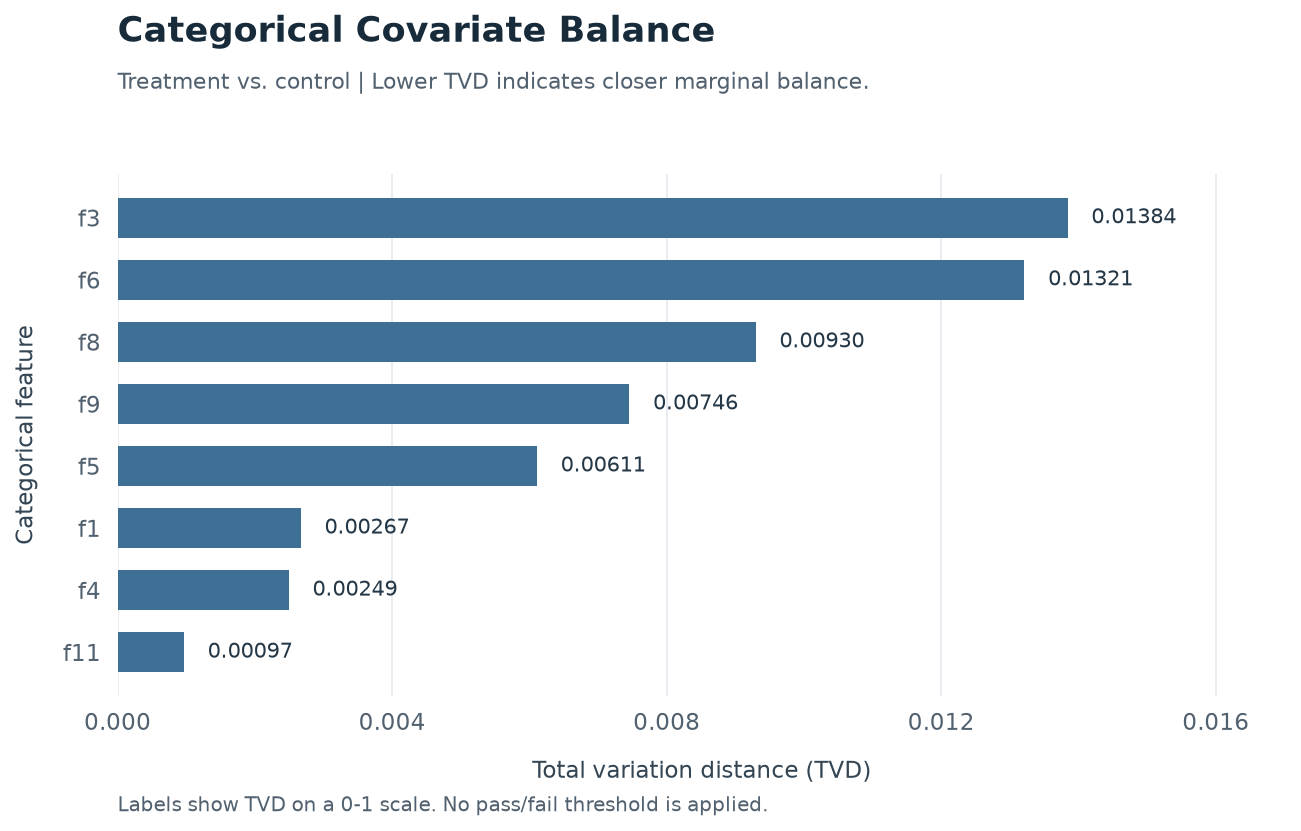

In [24]:
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

# Sort a copy so the existing balance table remains available in its original order.
plot_balance = balance.sort_values("tvd", ascending=False).copy()
max_tvd = plot_balance["tvd"].max()

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 11}):
    figure, ax = plt.subplots(figsize=(9.5, 5.7), dpi=150)
    figure.patch.set_facecolor("white")
    ax.set_facecolor("white")
    figure.subplots_adjust(left=0.12, right=0.94, top=0.79, bottom=0.18)

    ax.barh(
        plot_balance.index,
        plot_balance["tvd"],
        height=0.64,
        color="#3E7096",
        edgecolor="none",
        zorder=3,
    )
    ax.invert_yaxis()

    for position, value in enumerate(plot_balance["tvd"]):
        ax.text(
            value + max_tvd * 0.025,
            position,
            f"{value:.5f}",
            va="center",
            fontsize=10,
            color="#243746",
        )

    ax.set_xlim(0, max_tvd * 1.23)
    ax.set_xlabel("Total variation distance (TVD)", labelpad=12, color="#344554")
    ax.set_ylabel("Categorical feature", labelpad=12, color="#344554")
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E5EAF0", linewidth=0.8)
    ax.tick_params(axis="both", length=0, colors="#52616F", pad=8)
    for spine in ax.spines.values():
        spine.set_visible(False)

    figure.text(
        0.12, 0.945, "Categorical Covariate Balance",
        fontsize=17, fontweight="bold", color="#182B3A",
    )
    figure.text(
        0.12, 0.89,
        "Treatment vs. control | Lower TVD indicates closer marginal balance.",
        fontsize=10.5, color="#52616F",
    )
    figure.text(
        0.12, 0.045,
        "Labels show TVD on a 0-1 scale. No pass/fail threshold is applied.",
        fontsize=9.5, color="#52616F",
    )
    plt.show()

## Validation Summary

**Overall assessment: proceed to ITT estimation for the released benchmark sample, with the limitations below carried into the interpretation.** The saved diagnostics reveal no data-integrity failure, show allocation consistent with the assumed 85%/15% reference, and indicate small marginal covariate differences. They support continued analysis without establishing complete experimental validity.

| Validation area | Evidence from the saved results | Assessment |
| --- | --- | --- |
| Dataset size and schema | 13,979,592 rows; all 16 column names and types match | Pass |
| Missing values and variable domains | Zero nulls, invalid binary values, or non-finite feature values | Pass |
| Logical consistency | Zero exposed control observations; zero conversions without visits | Pass |
| Integrity audit total | 38/38 pass/fail checks pass; 12 additional feature summaries are informational | All implemented integrity checks pass |
| Observed allocation | 11,882,655 treatment and 2,096,937 control observations; treatment share 85.000013% | Consistent with an approximately 85%/15% split |
| Illustrative SRM | Pearson p = 0.998924; exact binomial p = 0.999402, assuming treatment probability exactly 0.85 | No mismatch detected under the assumption; formal SRM remains inconclusive without the exact expected allocation |
| Continuous covariates | All four absolute SMDs below 0.022; maximum 0.021270 for `f7` | Small mean differences relative to the 0.10 descriptive reference |
| Categorical covariates | TVD 0.000966-0.013841; largest category gap 1.379447 percentage points for `f3` | Small absolute marginal differences; descriptive assessment with no predefined pass/fail cutoff |

**Scope and remaining limitations.** The exact assignment probability for the released sample is unavailable, and marginal balance does not prove randomization or exclude joint or unmeasured differences. Treatment-assignment predictability was not assessed in this notebook. Missing stable user IDs, experiment/advertiser IDs, and timestamps prevent user-level deduplication, within-experiment allocation checks, clustering diagnostics, and time-based validation. Non-uniform negative-label sampling and pooled advertiser experiments limit generalization to the original campaign populations.

**Implication for the next stage.** Estimate the treatment-assignment contrast for `visit` as the primary outcome and `conversion` as the secondary outcome, reporting effect sizes and uncertainty for this released sample. Keep the full assigned arms in the ITT comparison and carry the sampling and pooled-experiment limitations into the results. The descriptive outcome rates in this notebook do not by themselves establish statistical significance or campaign-level business impact.